# ANLY 530 | KA1 Milestone 2 — Research Execution and Preliminary Findings
**Research question:** Do engineered features, regularization, or nonlinear modeling improve weekly center–meal demand forecasts relative to a historical mean baseline, and do improvements persist across time and demand levels?

**Run all cells in order.** This notebook produces measured results; the written report must use those outputs rather than assumed numbers. Original Milestone 1 notebook remains unchanged.

In [2]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
DATA = next((p for p in [Path('data/train.csv'), Path('/content/train.csv'), Path('../data/train.csv')] if p.exists()), None)
assert DATA is not None, 'Upload train.csv to Colab or place it at data/train.csv'
df = pd.read_csv(DATA)
print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (456548, 9)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


## 1. Data-quality audit and forecast information assumptions
- Each row is one `week`–`center_id`–`meal_id` observation.
- `num_orders` is the target. All demand summaries and segment thresholds are learned from training data only.
- Prices and promotion flags are **conditionally usable**: they must be finalized and accessible before the forecast for that week is issued. If not, models using these fields are scenario analyses, not deployable forecasts.
- No current-week orders or target-derived lag features are used. A future lag feature would require explicit cutoff/availability checks.
- Week number is known from the calendar. Center and meal IDs are assumed known at issuance.

In [3]:
required = {'week','center_id','meal_id','checkout_price','base_price','emailer_for_promotion','homepage_featured','num_orders'}
assert required.issubset(df.columns), f'Missing columns: {required-set(df.columns)}'
assert df['week'].between(1,145).all()
print('Missing values per required column:'); display(df[list(sorted(required))].isna().sum().to_frame('missing'))
print('Duplicate week-center-meal keys:',df.duplicated(['week','center_id','meal_id']).sum())
print('Nonpositive prices:', int(((df.checkout_price<=0)|(df.base_price<=0)).sum()))
print('Orders range:',df.num_orders.min(),df.num_orders.max())
print('Promotion flags:');display(df[['emailer_for_promotion','homepage_featured']].value_counts().to_frame('rows'))
assert df.duplicated(['week','center_id','meal_id']).sum()==0
assert df[list(required)].notna().all().all()
df=df.sort_values(['week','center_id','meal_id']).reset_index(drop=True)
development=df[df.week<=116].copy(); holdout=df[df.week.between(117,145)].copy()
assert set(development.week).isdisjoint(set(holdout.week))
print('Development:',development.shape,'Holdout:',holdout.shape)

Missing values per required column:


,missing
base_price,0
center_id,0
checkout_price,0
emailer_for_promotion,0
homepage_featured,0
meal_id,0
num_orders,0
week,0


Duplicate week-center-meal keys: 0
Nonpositive prices: 0
Orders range: 13 24299
Promotion flags:


rows
emailer_for_promotion homepage_featured        
0                     0                  388874
                      1                   30624
1                     1                   19231
                      0                   17819

Development: (361348, 9) Holdout: (95200, 9)


## 2. Feature construction
Compare **Ridge (raw features)** with **Ridge (engineered features)** to isolate the feature-engineering change, then compare engineered Ridge with nonlinear gradient boosting. Engineered price features are calculated using same-week prices and are only valid if those prices are available before issuance. No target-derived lags are included.

In [4]:
def make_features(frame):
    x=frame.copy()
    x['discount_amount']=(x.base_price-x.checkout_price).clip(lower=0)
    x['discount_pct']=x['discount_amount']/x.base_price.where(x.base_price>0, np.nan)
    x['discount_pct']=x['discount_pct'].replace([np.inf,-np.inf],np.nan).fillna(0).clip(0,1)
    x['any_promotion']=((x.emailer_for_promotion==1)|(x.homepage_featured==1)).astype(int)
    x['both_promotions']=((x.emailer_for_promotion==1)&(x.homepage_featured==1)).astype(int)
    return x
raw_features=['week','center_id','meal_id','checkout_price','base_price','emailer_for_promotion','homepage_featured']
engineered_features=raw_features+['discount_amount','discount_pct','any_promotion','both_promotions']
cat=['center_id','meal_id']

def linear_pipeline(features, model):
    num=[c for c in features if c not in cat]
    try: enc=OneHotEncoder(handle_unknown='ignore',sparse_output=True)
    except TypeError: enc=OneHotEncoder(handle_unknown='ignore',sparse=True)
    prep=ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),
        ('ids',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',enc)]),cat)])
    return Pipeline([('preprocess',prep),('model',model)])

# Tree models use compact numeric features with center/meal identifiers as categories encoded via
# training-only category maps (unseen IDs become -1). Ordinal codes are an approximation, not a
# natural ordering; this limitation is considered in the report.
def tree_matrix(training, future):
    tr=make_features(training); fu=make_features(future)
    cols=[c for c in engineered_features if c not in cat]+cat
    for col in cat:
        mapping={v:i for i,v in enumerate(sorted(tr[col].dropna().unique()))}
        tr[col]=tr[col].map(mapping).fillna(-1)
        fu[col]=fu[col].map(mapping).fillna(-1)
    return tr[cols].fillna(0),fu[cols].fillna(0)

def historical_predict(history,future):
    avg=history.groupby(['center_id','meal_id']).num_orders.mean()
    keys=pd.MultiIndex.from_frame(future[['center_id','meal_id']])
    p=avg.reindex(keys).to_numpy()
    return np.where(np.isnan(p),history.num_orders.mean(),p)

MODEL_NAMES=['Historical mean','Linear (raw)','Ridge (raw)','Ridge (engineered)','Gradient boosting (engineered)']
def predict(name,tr,va):
    if name=='Historical mean': p=historical_predict(tr,va)
    elif name=='Gradient boosting (engineered)':
        xtr,xva=tree_matrix(tr,va)
        # Limited complexity for feasible Colab CPU execution; no tuning on holdout.
        m=HistGradientBoostingRegressor(max_iter=100,max_leaf_nodes=15,learning_rate=0.08,
                                         l2_regularization=10.0,random_state=RANDOM_STATE)
        m.fit(xtr,tr.num_orders);p=m.predict(xva)
    else:
        engineered=name=='Ridge (engineered)'
        features=engineered_features if engineered else raw_features
        trf=make_features(tr) if engineered else tr
        vaf=make_features(va) if engineered else va
        model=LinearRegression() if name=='Linear (raw)' else Ridge(alpha=10.0)
        pipe=linear_pipeline(features,model)
        pipe.fit(trf[features],tr.num_orders)
        p=pipe.predict(vaf[features])
    return np.maximum(0,np.asarray(p,dtype=float))

def metrics(y,p):
    return {'mae':mean_absolute_error(y,p),
            'rmse':np.sqrt(mean_squared_error(y,p)),
            'bias_pred_minus_actual':float(np.mean(p-np.asarray(y)))}

## 3. Five expanding-window validation folds (12-week blocks)
Each model uses identical validation weeks. The training window expands, while the validation block contains all observations for its weeks. These are **12-week block forecasts**, not repeated one-week-ahead forecasts. The separate one-week diagnostic below addresses the forecast-horizon question.

In [5]:
fold_specs=[(1,56,57,68),(1,68,69,80),(1,80,81,92),(1,92,93,104),(1,104,105,116)]
rows=[]; diagnostics={}
for fold,(a,b,c,d) in enumerate(fold_specs,1):
    tr=development[development.week.between(a,b)]
    va=development[development.week.between(c,d)]
    print(f'Fold {fold}: train {a}–{b} ({len(tr):,} rows), validate {c}–{d} ({len(va):,} rows)')
    for name in MODEL_NAMES:
        p=predict(name,tr,va)
        rows.append({'fold':fold,'train_end':b,'validation_start':c,'validation_end':d,
                     'model':name,**metrics(va.num_orders,p)})
        if fold==5 and name in ['Historical mean','Ridge (raw)']:
            diagnostics[name]=pd.DataFrame({'actual':va.num_orders.to_numpy(),
                                            'fitted':p,'residual_actual_minus_fitted':va.num_orders.to_numpy()-p})
cv=pd.DataFrame(rows)
summary=cv.groupby('model')[['mae','rmse','bias_pred_minus_actual']].agg(['mean','std'])
display(summary.round(2))

Fold 1: train 1–56 (167,576 rows), validate 57–68 (37,868 rows)
Fold 2: train 1–68 (205,444 rows), validate 69–80 (38,726 rows)
Fold 3: train 1–80 (244,170 rows), validate 81–92 (38,965 rows)
Fold 4: train 1–92 (283,135 rows), validate 93–104 (38,883 rows)
Fold 5: train 1–104 (322,018 rows), validate 105–116 (39,330 rows)


mae          rmse         \
                                  mean   std    mean    std   
model                                                         
Gradient boosting (engineered)  134.88  3.48  253.13  18.67   
Historical mean                 120.76  7.69  270.10  40.39   
Linear (raw)                    144.72  2.90  268.72  32.81   
Ridge (engineered)              144.58  2.20  266.51  27.78   
Ridge (raw)                     144.67  2.89  268.74  32.82   

                               bias_pred_minus_actual         
                                                 mean    std  
model                                                         
Gradient boosting (engineered)                   4.16  15.82  
Historical mean                                  2.44  10.97  
Linear (raw)                                    15.83  15.43  
Ridge (engineered)                              17.07  13.48  
Ridge (raw)                                     15.75  15.41

### Fold-level MAE difference relative to the historical baseline
`difference = model MAE − baseline MAE`: **negative** means improvement over the baseline. A low average alone is not sufficient if performance deteriorates in several periods.

model,Gradient boosting (engineered),Historical mean,Linear (raw),Ridge (engineered),Ridge (raw)
fold,,,,,
1,131.09,126.50,144.13,142.86,144.04
2,132.97,130.29,149.07,148.42,148.99
3,139.02,110.83,142.50,143.92,142.45
4,133.20,117.98,146.00,143.59,145.96
5,138.12,118.19,141.92,144.14,141.90


model,Gradient boosting (engineered),Historical mean,Linear (raw),Ridge (engineered),Ridge (raw)
fold,,,,,
1,4.60,0.0,17.64,16.36,17.55
2,2.68,0.0,18.77,18.12,18.70
3,28.19,0.0,31.67,33.09,31.62
4,15.22,0.0,28.03,25.61,27.98
5,19.93,0.0,23.73,25.95,23.71


Number of folds beating baseline (negative MAE difference):


,folds_out_of_5
model,
Gradient boosting (engineered),0
Linear (raw),0
Ridge (engineered),0
Ridge (raw),0


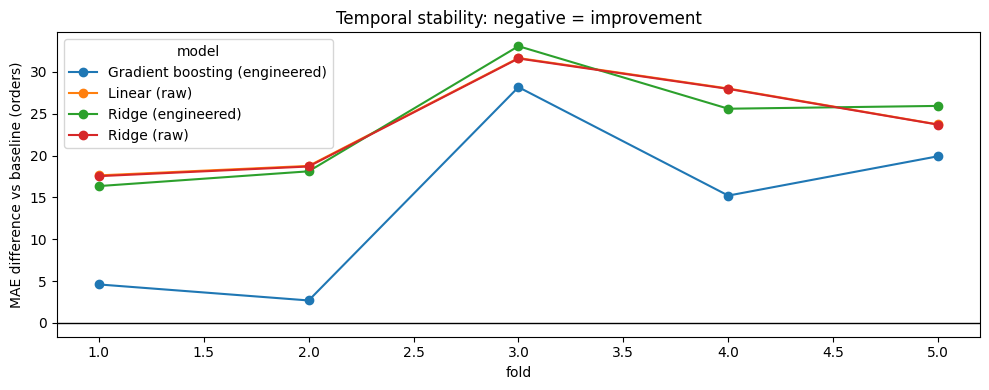

In [6]:
mae_by_fold=cv.pivot(index='fold',columns='model',values='mae')
delta=mae_by_fold.sub(mae_by_fold['Historical mean'],axis=0)
display(mae_by_fold.round(2));display(delta.round(2))
print('Number of folds beating baseline (negative MAE difference):')
display((delta.drop(columns='Historical mean')<0).sum().to_frame('folds_out_of_5'))
ax=delta.drop(columns='Historical mean').plot(marker='o',figsize=(10,4))
ax.axhline(0,color='black',linewidth=1);ax.set_ylabel('MAE difference vs baseline (orders)')
ax.set_title('Temporal stability: negative = improvement');plt.tight_layout();plt.show()

## 4. Residuals versus fitted: baseline and Ridge
A positive residual means actual orders exceeded the prediction (underforecasting). Look for increasing spread or systematic residuals at high fitted demand. The plot uses the fifth validation fold, not the holdout.

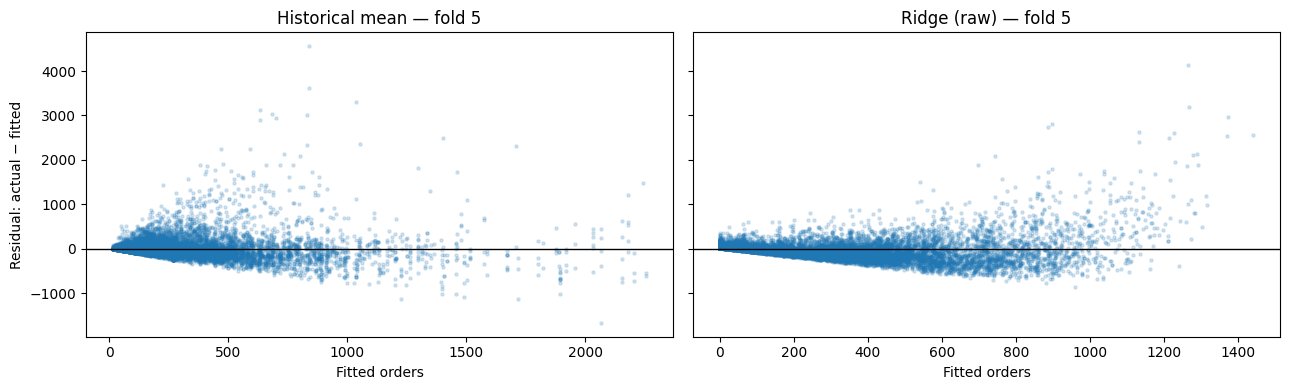

Historical mean top 10% actual-demand rows: 3954 MAE: 416.82 bias actual−fitted: 301.45
Ridge (raw) top 10% actual-demand rows: 3954 MAE: 363.7 bias actual−fitted: 325.63


In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,(name,diag) in zip(axes,diagnostics.items()):
    sample=diag.sample(n=min(12000,len(diag)),random_state=RANDOM_STATE)
    ax.scatter(sample.fitted,sample.residual_actual_minus_fitted,s=5,alpha=.18)
    ax.axhline(0,color='black',linewidth=1)
    ax.set_title(name+' — fold 5');ax.set_xlabel('Fitted orders')
axes[0].set_ylabel('Residual: actual − fitted');plt.tight_layout();plt.show()
for name,diag in diagnostics.items():
    high=diag.actual>=diag.actual.quantile(.9)
    print(name,'top 10% actual-demand rows:',high.sum(),
          'MAE:',round(np.mean(abs(diag.loc[high,'residual_actual_minus_fitted'])),2),
          'bias actual−fitted:',round(diag.loc[high,'residual_actual_minus_fitted'].mean(),2))

## 5. Low-, medium-, and high-demand validation segments
Segment thresholds are computed **only from each fold's training targets**, avoiding a target-distribution look-ahead. Segment labels on validation rows use actual demand for retrospective error analysis only; they are **not inputs to prediction**. These descriptive segments cannot be used as known future groups at deployment.

In [8]:
segment_rows=[]
for fold,(a,b,c,d) in enumerate(fold_specs,1):
    tr=development[development.week.between(a,b)];va=development[development.week.between(c,d)]
    q1,q2=tr.num_orders.quantile([1/3,2/3])
    segments=pd.cut(va.num_orders,[-np.inf,q1,q2,np.inf],labels=['Low','Medium','High'])
    for name in MODEL_NAMES:
        p=predict(name,tr,va)
        for segment in ['Low','Medium','High']:
            mask=(segments==segment).to_numpy()
            segment_rows.append({'fold':fold,'model':name,'segment':segment,'n':int(mask.sum()),
                                 **metrics(va.num_orders.to_numpy()[mask],p[mask])})
segment_cv=pd.DataFrame(segment_rows)
display(segment_cv.groupby(['segment','model'])[['mae','rmse','bias_pred_minus_actual']].mean().round(2))

mae    rmse  bias_pred_minus_actual
segment model                                                                 
High    Gradient boosting (engineered)  237.10  401.91                 -130.61
        Historical mean                 241.91  451.22                  -78.79
        Linear (raw)                    231.08  416.93                  -69.71
        Ridge (engineered)              230.98  412.02                  -70.69
        Ridge (raw)                     231.06  417.04                  -70.15
Low     Gradient boosting (engineered)   77.80  112.21                   74.59
        Historical mean                  43.15   68.61                   37.24
        Linear (raw)                     69.36  112.60                   32.80
        Ridge (engineered)               70.86  114.68                   36.09
        Ridge (raw)                      69.36  112.60                   32.94
Medium  Gradient boosting (engineered)   94.02  144.90                   63.24
        Historical mean                  83.01  125.49                   45.93
        Linear (raw)                    139.39  184.17                   82.40
        Ridge (engineered)              137.36  184.29                   83.71
        Ridge (raw)                     139.23  184.01                   82.42

## 6. Strict one-week-ahead diagnostic
At each origin, fit using all weeks observed through the origin and forecast **only the immediately following week**. Five origins are sampled within development (56, 68, 80, 92, 104) for feasibility. This diagnostic does not replace the five 12-week-block folds, and it is not exhaustive weekly rolling-origin evaluation.

In [9]:
one_week_rows=[]
for origin in [56,68,80,92,104]:
    tr=development[development.week<=origin];va=development[development.week==origin+1]
    for name in MODEL_NAMES:
        p=predict(name,tr,va)
        one_week_rows.append({'origin_week':origin,'forecast_week':origin+1,'model':name,
                              **metrics(va.num_orders,p)})
one_week_cv=pd.DataFrame(one_week_rows)
display(one_week_cv.pivot(index='forecast_week',columns='model',values='mae').round(2))
display(one_week_cv.groupby('model')[['mae','rmse']].mean().round(2))

model,Gradient boosting (engineered),Historical mean,Linear (raw),Ridge (engineered),Ridge (raw)
forecast_week,,,,,
57,131.02,115.49,136.53,136.97,136.54
69,150.34,162.00,184.81,188.23,184.83
81,108.73,89.73,116.76,117.12,116.67
93,121.25,114.19,128.37,127.63,128.33
105,132.03,87.99,125.43,127.02,125.44


,mae,rmse
model,,
Gradient boosting (engineered),128.67,223.41
Historical mean,113.88,227.10
Linear (raw),138.38,242.11
Ridge (engineered),139.39,242.40
Ridge (raw),138.36,242.17


## 7. Model choice and untouched final holdout
Primary metric: **MAE**, reflecting typical per-observation planning error. RMSE is a secondary safeguard against costly large misses, especially when demand ranges widely. Compare fold stability, segment errors, bias, and operational interpretability before choosing. Select using **development CV only**. The holdout (weeks 117–145) is evaluated **once** for the selected model; do not use it to retune or choose another model.

Selected by lowest development-block CV MAE: Historical mean
Interpretation check: also review temporal stability, high-demand errors, and one-week diagnostic above.
Final holdout metrics: {'mae': 109.84, 'rmse': np.float64(249.01), 'bias_pred_minus_actual': 12.86}


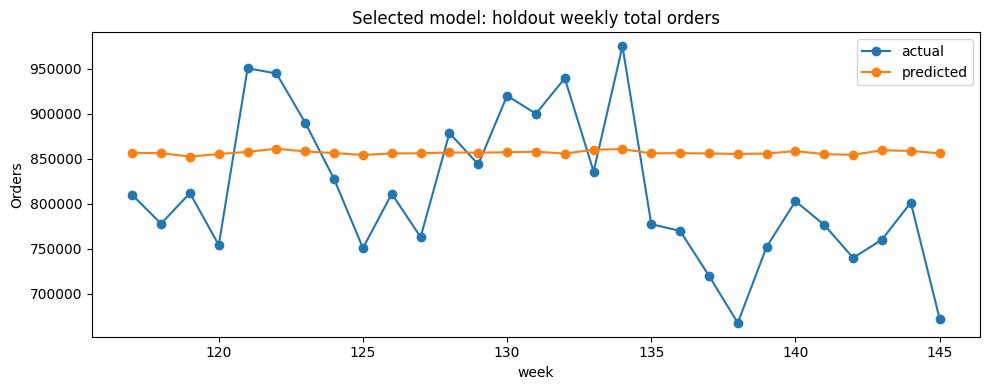

Caution: weekly totals aggregate row predictions; row-level MAE is the primary metric.


In [10]:
mean_mae=cv.groupby('model').mae.mean().sort_values()
selected=mean_mae.index[0]
print('Selected by lowest development-block CV MAE:',selected)
print('Interpretation check: also review temporal stability, high-demand errors, and one-week diagnostic above.')
holdout_pred=predict(selected,development,holdout)
print('Final holdout metrics:',{k:round(v,2) for k,v in metrics(holdout.num_orders,holdout_pred).items()})
weekly=pd.DataFrame({'week':holdout.week.to_numpy(),'actual':holdout.num_orders.to_numpy(),
                     'predicted':holdout_pred}).groupby('week')[['actual','predicted']].sum()
ax=weekly.plot(figsize=(10,4),marker='o',title='Selected model: holdout weekly total orders')
ax.set_ylabel('Orders');plt.tight_layout();plt.show()
print('Caution: weekly totals aggregate row predictions; row-level MAE is the primary metric.')

## 8. Reproducible outputs and research interpretation prompts
**Report actual measured values from the tables above.** Address:
1. Does feature engineering help compared with Ridge on the same raw features?
2. Does regularization help compared with unregularized linear regression?
3. Does nonlinear boosting improve MAE, and in how many folds?
4. Are gains sustained for low-, medium-, and high-demand observations?
5. Do residuals grow with fitted demand or show underforecasting of high-volume rows?
6. Does the one-week diagnostic support or qualify the 12-week-block conclusions?
7. Are prices and promotions truly known at the forecast cutoff? If not, mark those models nondeployable until verified.
8. If boosting wins average MAE but loses to Ridge in multiple periods, weigh stability, tail risk, maintenance cost, and interpretability; do not select purely by the best mean score.

**Limitations:** observational data, no causal effect claims, ordinal ID representation in boosting, no exogenous event variables, unknown operational feature availability, and only five sampled one-week origins.

In [12]:
out=Path('results');out.mkdir(exist_ok=True)
cv.to_csv(out/'milestone2_12week_cv.csv',index=False)
delta.to_csv(out/'milestone2_fold_mae_delta.csv')
segment_cv.to_csv(out/'milestone2_demand_segments.csv',index=False)
one_week_cv.to_csv(out/'milestone2_one_week_diagnostic.csv',index=False)
weekly.to_csv(out/'milestone2_holdout_weekly_totals.csv')
pd.DataFrame({'week':holdout.week.to_numpy(),'actual':holdout.num_orders.to_numpy(),
              'predicted':holdout_pred}).to_csv(out/'milestone2_holdout_predictions.csv',index=False)
print('Saved outputs to',out.resolve())

Saved outputs to /content/results
